# 03 — Model versions, E0–E6 and final decision

Part A explains model versions V1–V5. Part B follows the later E0–E6 run and the choice to retain V4. Internal validation, course development, other development panels and leaderboard evidence have different roles.


## Part A — Model development, V1–V5


In [1]:
import sys
from pathlib import Path
_REPO = Path.cwd().resolve()
if _REPO.name in {"notebooks", "experiments"}:
    _REPO = _REPO.parent
if not (_REPO / "data/manifests/approved_inputs.json").is_file():
    raise RuntimeError("Open from the repository root, notebooks folder, or experiments folder.")
if str(_REPO / "src") not in sys.path:
    sys.path.insert(0, str(_REPO / "src"))
import os
import tempfile
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "dragonthree-mpl"))
os.environ.setdefault("MPLBACKEND", "Agg")
import copy
import hashlib
import json
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix
from IPython.display import display
from dragonthree.project_io import (
    ROOT, READS, load_result, labeled_urls, text_group, install_data_guard, show_figure
)
RUN_TRAINING = False
NEW_CPU_BUDGET_SECONDS = None
VERSION_TO_TRAIN = "v3"
PRETRAINED_DIR = None
print("Model definitions + saved evidence only. Training enabled:", RUN_TRAINING)

Model definitions + saved evidence only. Training enabled: False


## 1. Data roles, metric definitions, and selection boundaries

All original v1–v5 validated models use 3,849 training records and 951 course development records.
Later cleaned-data studies use 3,730 and are in Notebook 03. Original submission checkpoints were
generally refitted on all 4,800 supplied records; their fit scores are not independent dev results.
FoxNews = 0, NBC = 1. Positive margins predict NBC.
Baseline checkpoint selection used course dev; the original later-model searches used training OOF
scores, while the broader project repeatedly inspected the same dev panel.

The original check used 3,849 training and 951 course development examples. The historical code below requires local approved data.

````python
train = labeled_urls("course_original_train")
dev = labeled_urls("course_dev")
assert len(train) == 3849 and len(dev) == 951
assert set(train.text.map(text_group)).isdisjoint(set(dev.text.map(text_group)))
split_table = pd.concat([train.assign(split="train"),dev.assign(split="dev")],ignore_index=True)
display(pd.crosstab(split_table["split"],split_table["label"]))
````


In [2]:
# Original split checks require the approved local course data.
def metrics_from_scores(y, score):
    """Binary metrics; caller must explicitly supply an approved development/internal panel."""
    y = np.asarray(y)
    pred = (np.asarray(score) > 0).astype(int)
    return {"n": len(y), "correct": int((pred == y).sum()),
            "accuracy": float(accuracy_score(y, pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
            "macro_f1": float(f1_score(y, pred, average="macro")),
            "roc_auc": float(roc_auc_score(y, score)),
            "confusion_matrix_Fox_NBC": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def original_grouped_folds(texts, y, seed=42, n_splits=3):
    """Original cleaned-text grouping, not the later event/template split."""
    groups = [text_group(t) for t in texts]
    mapping = {}
    for g, label in zip(groups, y):
        if g in mapping and mapping[g] != int(label):
            raise ValueError("Conflicting source labels in the same normalized-text group")
        mapping[g] = int(label)
    keys = sorted(mapping)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, va in cv.split(keys, [mapping[k] for k in keys]):
        a, b = {keys[i] for i in tr}, {keys[i] for i in va}
        yield np.array([i for i,g in enumerate(groups) if g in a]), np.array([i for i,g in enumerate(groups) if g in b])

label,FoxNews,NBC
split,,
dev,476,475
train,1896,1953


### V1 — hashed-word EmbeddingBag baseline

**Question:** how much source signal can a small bag-of-words neural model recover?
**Input:** cleaned text; 50,000 deterministic MD5 token buckets; empty input uses bucket 0.
**Architecture:** mean EmbeddingBag(50,000,128), Linear(128,128), ReLU, Linear(128,2).
**Training:** random initialization, Adam, LR 0.001, batch 64, five epochs, weight decay 0, seed 42.
Best dev accuracy selects the checkpoint; ties use lower dev loss. Recorded best epoch: 5.
**Recorded result:** 725/951 = 76.24%; not the hidden leaderboard score.
Source: baseline/model.py, baseline/train.py, baseline_seed42/metrics.json.

In [3]:
def hashed_inputs(texts, num_buckets=50000):
    ids, offsets = [], []
    for text in texts:
        offsets.append(len(ids))
        tokens = re.findall(r"[a-z0-9]+", text.lower())
        ids.extend([int(hashlib.md5(t.encode()).hexdigest(), 16) % num_buckets for t in tokens] or [0])
    return torch.tensor(ids, dtype=torch.long), torch.tensor(offsets, dtype=torch.long)

class BaselineV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.EmbeddingBag(50000, 128, mode="mean")
        self.fc = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))
    def forward(self, ids, offsets):
        return self.fc(self.embedding(ids, offsets))
    @torch.inference_mode()
    def decision_function(self, texts):
        self.eval()
        scores = []
        for start in range(0, len(texts), 64):
            logits = self(*hashed_inputs(texts[start:start+64]))
            scores.extend((logits[:, 1] - logits[:, 0]).numpy())
        return np.asarray(scores)
    def predict(self, texts):
        return (self.decision_function(texts) > 0).astype(int)

def fit_v1(texts, y, dev_texts, dev_y, seed=42):
    """Historical dev-selected five-epoch recipe; called only by an explicit new run."""
    torch.manual_seed(seed)
    torch.set_num_threads(2)
    model = BaselineV1()
    optimizer = torch.optim.Adam(model.parameters(), lr=.001, weight_decay=0)
    truth, dev_truth = torch.tensor(y, dtype=torch.long), torch.tensor(dev_y, dtype=torch.long)
    best, best_state, history = (-1.0, -float("inf")), None, []
    for epoch in range(1, 6):
        model.train()
        order = torch.randperm(len(texts)).tolist()
        for start in range(0, len(order), 64):
            idx = order[start:start+64]
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(*hashed_inputs([texts[i] for i in idx])), truth[idx])
            loss.backward()
            optimizer.step()
        model.eval()
        total_loss, correct = 0., 0
        with torch.no_grad():
            for start in range(0, len(dev_texts), 64):
                logits = model(*hashed_inputs(dev_texts[start:start+64]))
                target = dev_truth[start:start+64]
                total_loss += nn.functional.cross_entropy(logits, target, reduction="sum").item()
                correct += int((logits.argmax(1) == target).sum())
        key = (correct/len(dev_y), -total_loss/len(dev_y))
        history.append({"epoch": epoch, "dev_accuracy": key[0], "dev_loss": -key[1]})
        if key > best:
            best, best_state = key, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history

display(load_result("v1_metrics"))

{'architecture': 'course hashed-word EmbeddingBag(50000,128) + Linear(128,128)/ReLU/Linear(128,2)',
 'initialization': 'random; supplied weights not used',
 'label_mapping': {'FoxNews': 0, 'NBC': 1},
 'seed': 42,
 'epochs': 5,
 'batch_size': 64,
 'learning_rate': 0.001,
 'weight_decay': 0.0,
 'cpu_threads': 2,
 'python_version': '3.12.14',
 'torch_version': '2.9.1',
 'train_rows': 3849,
 'validation_rows': 951,
 'train_csv_sha256': '038e59245fd71d0da7601ba8e2207f08766f0c81fa2d8961f2f18048217e1e07',
 'val_csv_sha256': '4d12ef27eaa80a7e1c31d35269f95c9721464b2f13fab34e1dcf92eca895b512',
 'best_epoch': 5,
 'validation_accuracy': 0.7623554153522608,
 'majority_class': 'NBC',
 'majority_validation_accuracy': 0.49947423764458465,
 'training_seconds': 4.545059332995152,
 'validation_inference_seconds': 0.01055991599423578,
 'avg_inference_ms': 0.011104012612235311,
 'confusion_matrix_labels': ['FoxNews', 'NBC'],
 'confusion_matrix_rows_actual_cols_predicted': [[388, 88], [138, 337]],
 'score_s

### V2 — word and within-word character TF-IDF + linear SVM

**Change:** word 1–2-grams plus char-wb 3–5-grams.
**Parameters:** lowercase, Unicode accent stripping, sublinear TF, separate L2 block normalization;
character min_df=2 and max_features=100,000; one-character word tokens retained.
LinearSVC C=4, dual=True, max_iter=5,000, seed 42; threshold 0.
Selection: grouped three-fold training-only CV over eight specified candidates.
**Recorded result:** 756/951 = 79.50%. Exact chosen spec appears below.

## 4. V3 — cross-space character features

**Change:** char 2–5-grams over the full text; min_df=2, cap=120,000; word 1–2-grams, min_df=1.
SVM C=4, max_iter=10,000. Divide raw margin by 0.776760627876633, then subtract threshold −0.05.
The normalized margin is not a probability. Scale and threshold are historical training-OOF choices.
**Recorded result:** 775/951 = 81.49%; same original split as v1/v2.
Source: v2/experiments.py and v3/search.py; manifests show the full candidate rankings.

In [4]:
class LexicalV2V3:
    def __init__(self, version="v3", C=4., threshold=None):
        if version not in {"v2", "v3"}:
            raise ValueError(version)
        self.version, self.C = version, C
        self.scale = 1. if version == "v2" else 0.776760627876633
        self.threshold = (0. if version == "v2" else -.05) if threshold is None else threshold
    def make_vectors(self):
        shared = dict(lowercase=True, strip_accents="unicode", dtype=np.float64, sublinear_tf=True)
        word = TfidfVectorizer(ngram_range=(1,2), min_df=1, token_pattern=r"(?u)\b\w+\b", **shared)
        char = TfidfVectorizer(analyzer="char_wb" if self.version=="v2" else "char",
            ngram_range=(3,5) if self.version=="v2" else (2,5), min_df=2,
            max_features=100000 if self.version=="v2" else 120000, **shared)
        return [word, char]
    def fit(self, texts, y, sample_weight=None):
        self.vectors = self.make_vectors()
        X = sparse.hstack([v.fit_transform(texts) for v in self.vectors], format="csr")
        self.clf = LinearSVC(C=self.C, dual=True, max_iter=5000 if self.version=="v2" else 10000,
                             random_state=42).fit(X, y, sample_weight=sample_weight)
        return self
    def transform(self, texts):
        return sparse.hstack([v.transform(texts) for v in self.vectors], format="csr")
    def decision_function(self, texts):
        return self.clf.decision_function(self.transform(texts))/self.scale - self.threshold
    def predict(self, texts):
        return (self.decision_function(texts) > 0).astype(int)

v2_selection = load_result("v2_selection")
display(pd.DataFrame(v2_selection["ranking"])[["candidate","cv_accuracy","spec"]])
display(load_result("v3_comparison")["selected_recipe"])

,candidate,cv_accuracy,spec
0,word_character_svm_c4,0.798909,"{'name': 'word_character_svm_c4', 'blocks': ['..."
1,word_character_svm_c1,0.796830,"{'name': 'word_character_svm_c1', 'blocks': ['..."
2,word_character_logistic,0.793193,"{'name': 'word_character_logistic', 'blocks': ..."
3,word_bigram_svm_c1,0.787737,"{'name': 'word_bigram_svm_c1', 'blocks': ['wor..."
4,word_bigram_svm_c4,0.787477,"{'name': 'word_bigram_svm_c4', 'blocks': ['wor..."
5,nb_word_bigram_logistic,0.785139,"{'name': 'nb_word_bigram_logistic', 'blocks': ..."
6,word_unigram_logistic,0.781502,"{'name': 'word_unigram_logistic', 'blocks': ['..."
7,character_svm,0.779423,"{'name': 'character_svm', 'blocks': ['char'], ..."


{'name': 'short_char',
 'members': ['short_char'],
 'cv_accuracy': 0.8077422707196674,
 'threshold': -0.05,
 'uncalibrated_cv_accuracy': 0.8046245778124188,
 'scales': {'short_char': 0.776760627876633}}

### V4 — structural features and length interactions

**Question:** can title structure and semantic representations complement lexical features?
Numeric features are computed from permitted text only. Fourteen features: character/word counts;
mean/max/std word length; fractions of short/function/unique words; apostrophes, commas, colons,
question marks, non-ASCII characters and uppercase characters.
Standardize on the fitting fold. Clip standardized character count to [−3,3].
Concatenate lexical features, 0.5 × standardized numeric features, and lexical × clipped length × λ.
Two squared-hinge SVMs use λ=1 and 0.25, C=4, max_iter=30,000, seed 42.
**Source:** v4/structural.py and advanced_search.py.

In [5]:
FUNCTION_WORDS = set("a an the and or but of to in on at for with from by as is are was were be been being it its this that these those he she they we you i his her their our your not no will would can could should has have had do does did over under after before about into out up down how what why who when where".split())
FEATURE_NAMES = ["characters","words","mean_word_length","max_word_length","std_word_length",
                 "short_word_fraction","function_word_fraction","unique_word_fraction",
                 "apostrophes","commas","colons","question_marks","non_ascii","uppercase"]

def numeric_features(texts):
    rows = []
    for text in texts:
        tokens = re.findall(r"[a-z0-9]+", text.lower())
        lengths = [len(t) for t in tokens] or [0]
        count = max(len(tokens), 1)
        rows.append([len(text),len(tokens),np.mean(lengths),max(lengths),np.std(lengths),
            sum(len(t)<=3 for t in tokens)/count, sum(t in FUNCTION_WORDS for t in tokens)/count,
            len(set(tokens))/count,text.count("'")+text.count("’"),text.count(","),
            text.count(":"),text.count("?"),sum(ord(c)>127 for c in text),sum(c.isupper() for c in text)])
    return np.asarray(rows, dtype=np.float64)

def structure_matrix(lexical, numeric, scaler, interaction):
    z = scaler.transform(numeric)
    return sparse.hstack([lexical, sparse.csr_matrix(z*.5),
        lexical.multiply((np.clip(z[:,0], -3, 3)*interaction)[:,None])], format="csr")

### V4 — two MiniLM models and the final fusion

**Pretrained model:** sentence-transformers/all-MiniLM-L6-v2,
revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41.
**Training:** seeds 42/43; attention-mask mean pooling and L2 normalization; 384→1 linear head;
binary cross-entropy; AdamW; encoder LR 2e−5, head LR 1e−3; decay .01; clip gradient norm 1;
batch 32; token limit 64. Logistic regression C=10 initializes the head using frozen embeddings.
Stop after epoch 3, retaining a learning-rate schedule based on four total epochs.
**Fusion:** 75% normalized lexical average + 25% normalized neural average; threshold −0.10.
Exact normalization values are read from the archived manifest below.

Transformers is needed only for a deliberately enabled new v4/v5 run. The functions accept an
explicit local pretrained directory and never download a checkpoint automatically.
**Sources:** v4/finetune.py, build.py, export.py, results/validated_manifest.json.

In [6]:
def normalize_rows(x):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-10)

def local_encoder_components(pretrained_dir):
    from transformers import AutoModel, AutoTokenizer
    p = Path(pretrained_dir)
    if not p.is_dir():
        raise FileNotFoundError("Supply the fixed-revision local pretrained directory.")
    tok = AutoTokenizer.from_pretrained(p, local_files_only=True, clean_up_tokenization_spaces=False)
    encoder = AutoModel.from_pretrained(p, local_files_only=True, add_pooling_layer=False)
    return tok, encoder

@torch.inference_mode()
def frozen_embeddings(texts, pretrained_dir, layer=-1):
    tok, encoder = local_encoder_components(pretrained_dir)
    encoder.eval()
    chunks = []
    for start in range(0, len(texts), 64):
        t = tok(texts[start:start+64], padding=True, truncation=True, max_length=64, return_tensors="pt")
        output = encoder(**t, output_hidden_states=True)
        hidden = output.hidden_states[layer]
        mask = t["attention_mask"].unsqueeze(-1)
        pooled = (hidden*mask).sum(1)/mask.sum(1).clamp_min(1)
        chunks.append(nn.functional.normalize(pooled, p=2, dim=1).numpy())
    return np.concatenate(chunks)

class FineMiniLM(nn.Module):
    def __init__(self, pretrained_dir):
        super().__init__()
        self.tokenizer, self.encoder = local_encoder_components(pretrained_dir)
        self.head = nn.Linear(384, 1)
    def forward(self, ids, mask):
        hidden = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        e = (hidden*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
        return self.head(nn.functional.normalize(e,p=2,dim=1)).squeeze(1)
    @torch.inference_mode()
    def score(self, texts):
        self.eval()
        out = []
        for start in range(0, len(texts), 64):
            t = self.tokenizer(texts[start:start+64], padding=True, truncation=True,
                               max_length=64, return_tensors="pt")
            out.append(self(t["input_ids"],t["attention_mask"]).numpy())
        return np.concatenate(out)

def fine_tune_minilm(texts, y, pretrained_dir, seed, frozen):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = FineMiniLM(pretrained_dir)
    init = LogisticRegression(C=10.,solver="liblinear",max_iter=2000,random_state=42).fit(frozen,y)
    with torch.no_grad():
        model.head.weight.copy_(torch.from_numpy(init.coef_).float())
        model.head.bias.copy_(torch.from_numpy(init.intercept_).float())
    tokens = model.tokenizer(texts,padding=True,truncation=True,max_length=64,return_tensors="pt")
    optimizer = torch.optim.AdamW([
        {"params":model.encoder.parameters(),"lr":2e-5},
        {"params":model.head.parameters(),"lr":1e-3}], weight_decay=.01)
    targets = torch.tensor(y,dtype=torch.float32)
    total_steps, step = 4*math.ceil(len(y)/32), 0
    for epoch in range(1,4):
        model.train()
        order = rng.permutation(len(y))
        for start in range(0,len(order),32):
            idx = order[start:start+32]
            length = int(tokens["attention_mask"][idx].sum(1).max())
            optimizer.zero_grad(set_to_none=True)
            logits = model(tokens["input_ids"][idx,:length],tokens["attention_mask"][idx,:length])
            loss = nn.functional.binary_cross_entropy_with_logits(logits,targets[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
            step += 1
            for group,rate in zip(optimizer.param_groups,[2e-5,1e-3]):
                group["lr"] = rate*max(.1,1-step/total_steps)
    return model.eval()

class EnsembleV4:
    def __init__(self, pretrained_dir):
        self.pretrained_dir = pretrained_dir
        self.scales = [0.9255566836299168, 0.9241684716764983]
        self.neural_scale = 3.1162887335392746
    def fit(self, texts, y):
        torch.set_num_threads(4)
        self.vectors = LexicalV2V3("v3").make_vectors()
        L = sparse.hstack([v.fit_transform(texts) for v in self.vectors],format="csr")
        N = numeric_features(texts)
        self.scaler = StandardScaler().fit(N)
        self.lexical = [LinearSVC(C=4.,dual=True,max_iter=30000,random_state=42).fit(
            structure_matrix(L,N,self.scaler,interaction),y) for interaction in [1.,.25]]
        frozen = frozen_embeddings(texts,self.pretrained_dir)
        self.neural = [fine_tune_minilm(texts,y,self.pretrained_dir,seed,frozen) for seed in [42,43]]
        return self
    def lexical_features(self,texts):
        return sparse.hstack([v.transform(texts) for v in self.vectors],format="csr")
    def decision_function(self,texts):
        L, N = self.lexical_features(texts), numeric_features(texts)
        lexical = np.mean([model.decision_function(structure_matrix(L,N,self.scaler,interaction))/scale
            for model,interaction,scale in zip(self.lexical,[1.,.25],self.scales)],axis=0)
        neural = np.mean([m.score(texts) for m in self.neural],axis=0)/self.neural_scale
        return .75*lexical+.25*neural-(-.10)
    def predict(self,texts):
        return (self.decision_function(texts)>0).astype(int)

v4_evidence = load_result("v4_manifest")
display(v4_evidence["recipe"])
print("Recorded v4:",v4_evidence["validation_correct"],"/",v4_evidence["validation_rows"])

{'members': [{'spec': {'name': 'svm_interact1_c4',
    'kind': 'svm',
    'C': 4.0,
    'interaction': 1.0},
   'score_scale': 0.9255566836299168},
  {'spec': {'name': 'svm_interact025_c4',
    'kind': 'svm',
    'C': 4.0,
    'interaction': 0.25},
   'score_scale': 0.9241684716764983}],
 'neural_seeds': [42, 43],
 'epoch': 3,
 'schedule_total_epochs': 4,
 'learning_rate': 2e-05,
 'neural_scale': 3.1162887335392746,
 'semantic_weight': 0.25,
 'threshold': -0.10000000000000003,
 'cv_accuracy': 0.8383995843076124}

Recorded v4: 810 / 951


### V5 — frozen layer-3 embedding + sparse structural SVM

**Source:** v5_90pct_attempt/hybrid_search.py and hybrid_selection.json.
Selected representation is mean pooling of hidden_states[3] from the original frozen MiniLM,
then L2 normalization. Embedding dimension 384, multiplier 1.5; join it with v3 lexical,
standardized numeric, and λ=.25 length-interaction features. SVM C=4, max_iter=20,000.
Divide its raw margin by 1.005554992263655 and blend 50/50 with v4's **already threshold-adjusted**
margin. The final v5 threshold is −.05. This detail avoids subtracting the v4 threshold twice.
**Recorded result:** 812/951 = 85.38%; only two more correct than v4, and two fewer on historical
external dev (140 vs 142/306). A stable improvement or 90% result was not established.

In [7]:
class HybridV5:
    def __init__(self, fitted_v4, pretrained_dir):
        self.v4, self.pretrained_dir = fitted_v4, pretrained_dir
    def fit(self, texts, y):
        # V5 fits its own lexical transforms to the fitting split, as the historical hybrid did.
        self.vectors = LexicalV2V3("v3").make_vectors()
        L = sparse.hstack([v.fit_transform(texts) for v in self.vectors],format="csr")
        N = numeric_features(texts)
        self.scaler = StandardScaler().fit(N)
        E = frozen_embeddings(texts,self.pretrained_dir,layer=3)
        X = sparse.hstack([structure_matrix(L,N,self.scaler,.25),sparse.csr_matrix(1.5*E)],format="csr")
        self.clf = LinearSVC(C=4.,dual=True,max_iter=20000,random_state=42).fit(X,y)
        return self
    def decision_function(self,texts):
        L = sparse.hstack([v.transform(texts) for v in self.vectors],format="csr")
        E = frozen_embeddings(texts,self.pretrained_dir,layer=3)
        X = sparse.hstack([structure_matrix(L,numeric_features(texts),self.scaler,.25),
                          sparse.csr_matrix(1.5*E)],format="csr")
        raw = self.clf.decision_function(X)
        return .5*raw/1.005554992263655+.5*self.v4.decision_function(texts)-(-.05)
    def predict(self,texts):
        return (self.decision_function(texts)>0).astype(int)

display(load_result("v5_selection")["selected"])
display(load_result("v5_results").get("candidate_validation",{}))

{'index': 7,
 'spec': {'representation': 'mean3', 'weight': 1.5, 'C': 4.0},
 'scale': 1.005554992263655,
 'hybrid_weight': 0.5,
 'threshold': -0.050000000000000044,
 'cv_accuracy': 0.8396986230189659}

{'accuracy': 0.8538380651945321,
 'correct': 812,
 'rows': 951,
 'scope': 'Reused local development split, not hidden leaderboard.'}

### Recorded model comparison (no new model evaluation)

Course counts are sourced from v1/v3/v4/v5 machine results; historical external counts are from
the handoff's original-version audit. All rows refer to original training conditions.
One course-dev prediction is ~0.105 percentage points. The chart is not a confidence interval or
a fresh leaderboard result. Repeated development-set use limits claims of generalization.

,version,course_correct,course_n,historical_external_correct,external_n,course_accuracy_pct,external_accuracy_pct
0,v1,725,951,145,306,76.235542,47.385621
1,v2,756,951,128,306,79.495268,41.830065
2,v3,775,951,130,306,81.493165,42.483660
3,v4,810,951,142,306,85.173502,46.405229
4,v5,812,951,140,306,85.383807,45.751634


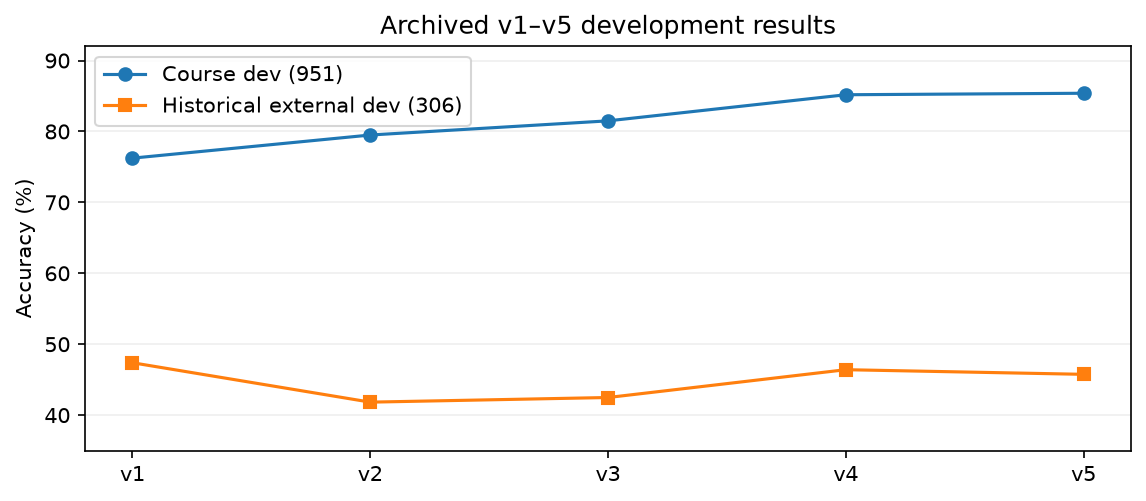

Only screenshot-verified historical public score: 75.5% on 8,000 examples.
No later leaderboard score or exact version attribution is established by this notebook.


In [8]:
course_correct = [load_result("v1_metrics")["validation_accuracy"]*951,756,775,810,812]
comparison = pd.DataFrame({
    "version":["v1","v2","v3","v4","v5"],
    "course_correct":[int(round(x)) for x in course_correct],
    "course_n":[951]*5,"historical_external_correct":[145,128,130,142,140],"external_n":[306]*5})
comparison["course_accuracy_pct"] = 100*comparison.course_correct/comparison.course_n
comparison["external_accuracy_pct"] = 100*comparison.historical_external_correct/comparison.external_n
display(comparison)
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(comparison.version,comparison.course_accuracy_pct,"o-",label="Course dev (951)")
ax.plot(comparison.version,comparison.external_accuracy_pct,"s-",label="Historical external dev (306)")
ax.set(ylabel="Accuracy (%)",title="Archived v1–v5 development results",ylim=(35,92))
ax.grid(axis="y",alpha=.2)
ax.legend()
show_figure(fig)
print("Only screenshot-verified historical public score: 75.5% on 8,000 examples.")
print("No later leaderboard score or exact version attribution is established by this notebook.")

### Original CV procedure and inference packaging

The original v2/v3/v4 searches fitted learned transforms inside each training fold, selected a recipe,
fitted the full original training split, then checked course development. The generic helper below
shows OOF evaluation for a supplied fixed recipe; it does not launch a grid or select on development.
Full historical search spaces and export code are available in source_archive.

Leaderboard export is separate from notebook training: provide get_model() or a no-argument
Model/NewsClassifier, predict(batch) or logits, and prepare_data(csv_path) with exactly one input
per CSV row in order. Ensembles must package all members in one checkpoint.
V4's archived runtime uses a bundled tokenizer and Torch implementation, not a runtime Transformers
download. The recorded validated export parity error is ~2.98e−7. The local 8,000-input v4 timing
(~12.48 s, four threads, repeated course inputs) is not a server guarantee.
The supplied notebook package does not invent or replace missing trained binary checkpoints.

In [9]:
def fixed_recipe_oof(factory, texts, y, seed=42):
    """For a deliberate future training run only; no execution in default review mode."""
    y = np.asarray(y)
    score = np.zeros(len(y))
    for tr, va in original_grouped_folds(texts,y,seed):
        model = factory().fit([texts[i] for i in tr],y[tr])
        score[va] = model.decision_function([texts[i] for i in va])
    return score

### Historical training entry point

This is the original optional launch example, shown for reference. The shared notebook reviews saved evidence.

````python
if RUN_TRAINING:
    import subprocess
    import sys
    if not isinstance(NEW_CPU_BUDGET_SECONDS,(int,float)) or NEW_CPU_BUDGET_SECONDS <= 0:
        raise ValueError("Set a newly authorized positive CPU budget.")
    if VERSION_TO_TRAIN in {"v4","v5"} and not PRETRAINED_DIR:
        raise ValueError("Provide the fixed-revision local MiniLM directory; no auto-download.")
    command = [sys.executable,str(ROOT/"scripts/train_historical.py"),"--version",VERSION_TO_TRAIN,
               "--cpu-budget",str(NEW_CPU_BUDGET_SECONDS)]
    if PRETRAINED_DIR:
        command += ["--pretrained-dir",str(PRETRAINED_DIR)]
    subprocess.run(command,cwd=ROOT,check=True)
else:
    print("No model training, checkpoint export, or new development prediction was performed.")
````


## Part B — Approved E0–E6 experiments

The saved results below document the continuation, the development-set comparison, the gate and deployment verification.


### Approved experimental scope

The team approved E1–E6 on 2026-11-21, with E0 as foundation work. The total new CPU allowance was **1,800 seconds**. The earlier 298.88928-second run was closed separately.

| Work | CPU cap in seconds |
|---|---:|
| E1 nested validation | 600 |
| E2 locked candidate confirmation | 300 |
| E4 conditional V4 migration | 600 |
| Other work, including E0 | 300 |

E4 was conditional on the original E1 and E2 gates. It was recorded as not started after the required checks failed. The authorized run kept the original models and sealed or teacher test data untouched. It did not authorize new collection, development-based reranking or a Git push. The two historical E1 configurations remain in the full local project. One preserves the original paths and the other records the later path migration.

### E2 reproduction boundary

This share includes the [saved E2 comparison](experiments/New%20Experiments/E2/results.json). Reproducing the locked fits requires the original approved training audit and development snapshots, as well as the frozen E0 digest manifest expected at `configs/data_manifest.json`. The [approved-input manifest](data/manifests/approved_inputs.json) describes input roles and paths. The three reduced team-review tables have different schemas and cannot substitute for the frozen inputs. E2 checks the original input digests before use.


## 1. Review setup and input boundaries

All result paths below are literal entries in an allowlist. The notebook reads only generated aggregates, approved prediction analyses, and locally generated figures. It does not discover datasets, open original raw metadata, or load a model checkpoint. The protected external test and teacher hidden test remain untouched.


In [ ]:
from pathlib import Path
import json
import csv
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if ROOT.name in {"notebooks", "experiments"}:
    ROOT = ROOT.parent
if not (ROOT / "src" / "dragonthree").is_dir():
    raise RuntimeError("Open this notebook from the repository root, notebooks folder, or experiments folder.")
RUN = ROOT / "experiments" / "New Experiments"
ALLOWED = {
    "audit": "E0/data_audit.json", "baseline": "E0/baseline_metrics.json",
    "nested": "E1/nested_results.json", "nested_summary": "E1/summary.json",
    "locked": "E2/results.json", "master": "E3/results_master.json",
    "table": "E3/experiment_table.json", "errors": "E3/error_transitions.json",
    "intervals": "E3/development_paired_intervals.json",
    "slices": "E3/publisher_length_slices.csv", "e4": "E4/gate_decision.json",
    "freeze": "E5/final_decision.json", "runtime": "E6/runtime.json",
}

def saved(key):
    expected = RUN / ALLOWED[key]
    if not expected.exists():
        display(Markdown("**Pending:** `" + ALLOWED[key] + "`"))
        return None
    if expected.resolve() != expected:
        raise PermissionError("Redirected result path rejected.")
    if expected.suffix == ".csv":
        return pd.read_csv(expected)
    return json.loads(expected.read_text())

print("Review mode: saved evidence only; no training or prediction.")


## 2. E0 foundation — approved data and the original V4 reference

**Question:** Do the approved snapshots match the recorded preprocessing and model provenance?

The audit preserves the historical data version rather than silently editing rows before cache continuation. It checks the 8,096 approved training-origin records and the named development panels. A reproducible 120-record review queue is supplied separately; its existence does not mean that independent human review has occurred.

The original **validated** V4 was fitted on 3,849 course training rows. Its development scores may be reproduced. The separate **submission** V4 was fitted on all 4,800 provided rows, including the 951 development rows; it must not be assigned an independent score on those same 951 rows.

Sources: `E0/data_audit.json`, `E0/baseline_metrics.json`, `E0/original_model_provenance.json`.


### Audit approved inputs and establish the V4 baseline

Source: [audit_and_baseline.py](src/dragonthree/audit_and_baseline.py)


In [2]:
audit = saved("audit")
baseline = saved("baseline")
if audit:
    display(pd.DataFrame([{"origin": k, "rows": v} for k, v in audit["origin_counts"].items()]))
    display({k: audit[k] for k in ["label_or_preprocess_mismatches", "duplicate_text_groups", "conflicting_label_text_groups", "approved_dev_exact_text_overlap_rows", "human_review_status"]})
if baseline:
    display(pd.DataFrame([{"panel": k, **v} for k, v in baseline["panels"].items()]).drop(columns=["confusion_matrix"]))


,origin,rows
0,course,3730
1,legacy,1566
2,paired,800
3,new,2000


{'label_or_preprocess_mismatches': [],
 'duplicate_text_groups': 0,
 'conflicting_label_text_groups': 0,
 'approved_dev_exact_text_overlap_rows': {'course_dev': 0,
  'legacy_dev': 0,
  'paired_dev': 0},
 'human_review_status': 'A reproducible review queue is supplied; independent human review is not claimed.'}

,panel,n,correct,accuracy,balanced_accuracy,macro_f1,auc,fox_recall,nbc_recall
0,course_dev,951,810,0.851735,0.851751,0.851703,0.922751,0.836134,0.867368
1,legacy_dev,306,142,0.464052,0.464052,0.424733,0.412705,0.202614,0.725490
2,paired_dev,200,115,0.575000,0.575000,0.574479,0.639500,0.610000,0.540000


## 3. E1 — complete the historical nested selection procedure

**Question:** Does an augmentation procedure improve the new-data internal panel while protecting course performance, NBC recall, and the old internal panel?

The missing outer fold is `seed5192_outer2`, with inner seed `51922`. The historical design is preserved: representations A–D, C values 0.25/1/4/16, and thresholds from -0.50 to +0.50 in steps of 0.05. Features and model coefficients are fitted only within the appropriate training fold. Legacy and paired training-origin rows form an internal selection/evaluation panel; they do not fit vocabulary, IDF, or coefficients in this study.

A uses course features and course fitting. B adds weighted new fitting rows without changing course TF-IDF. C keeps the course vocabulary and refits IDF on course+new. D also expands vocabulary. Each new-data class receives total loss weight `100 × course_fold_rows / 3730`.

The primary nested comparison is the selected augmentation procedure versus **equally tuned A**. Averaging per-record correctness across complete partitions precedes the paired group bootstrap; this is not a score-averaged ensemble. Intervals are conditional on these reused training partitions. Fixed-grid curves and nested selection estimates are different evaluation levels.

Sources: [historical experiment protocols](02_Historical_Experiments_and_Results.ipynb); new `E1/nested_results.json`, `E1/input_verification.json`, `E1/compatibility_anchor.json`, and logs.

The historical in-sample diagnostic log covers only eight outer folds. Completing all nine OOF folds does not turn those partial training diagnostics into nine-fold statistics; the figures below use the complete OOF results.


### Historical E1 input preparation

The original helper records approved input paths and their hashes before a continuation. It is preserved here as disabled source. The Desktop share copy reviews saved results.


In [ ]:
if False:  # Historical command. Kept disabled in this review notebook.
    """Record approved cache hashes for E1; no other paths are traversed."""
    from pathlib import Path
    import hashlib
    import json
    ROOT=Path(__file__).resolve().parents[2]
    
    def main():
        cache='experiments/historical/v3_feature_regularization_2026-10-29/'
        files={'audited_training':'data/approved/audited_training.jsonl',
               'folds':cache+'folds.json','plan':cache+'preregistered_plan.json',
               'locked_selection':cache+'final_selection.json',
               'fixed_grid':cache+'fixed_grid_complete.npz','nested_oof':cache+'nested_oof.npz',
               'outer_choices':cache+'outer_choices.json',
               'historical_training_scores':cache+'training_scores.json',
               'historical_nested_results':cache+'nested_results.json'}
        entries={k:{'path':v,'sha256':hashlib.sha256((ROOT/v).read_bytes()).hexdigest()} for k,v in files.items()}
        config={'stage_id':'E1','authorization_scope':'base1800','cpu_budget_seconds':590,
                'max_fits':49,'inputs':entries,'compatibility_anchor':{'enabled':True}}
        with (ROOT/'configs/E1.prepared.json').open('x') as handle:
            handle.write(json.dumps(config,indent=2)+'\n')
        print('Approved E1 input configuration created; only explicit training caches were read.')
    if __name__=='__main__':main()


### Continue nested group-disjoint validation

Source: [e1_validation.py](src/dragonthree/e1_validation.py)


### Define fold-local features, selection and metrics

Source: [v3_validation.py](src/dragonthree/v3_validation.py)


In [3]:
nested = saved("nested")
if nested:
    selected = [row for row in nested["policies"] if row["policy"] in ("A_fixed", "A_joint", "augmented_joint")]
    display(pd.DataFrame([{"policy": row["policy"], "panel": panel, **row[panel]} for row in selected for panel in ("course", "new", "old")]))
    display(nested.get("gate_checks", {}))
    display({"internal_gate_passed": nested["internal_gate_passed"],
             "completed_outer_folds": nested.get("nested_completed_outer_folds"),
             "complete_partitions": nested.get("nested_complete_partitions")})
    display(pd.DataFrame.from_dict(nested["primary_paired_deltas_vs_tuned_A"], orient="index"))


,policy,panel,n,accuracy,accuracy_by_seed,correct_by_seed,balanced_accuracy,macro_f1,roc_auc,fox_recall,nbc_recall
0,A_fixed,course,3730,0.792672,"[0.7892761394101877, 0.7994638069705093, 0.789...","[2944, 2982, 2944]",0.792390,0.792388,0.872412,0.821561,0.763220
1,A_fixed,new,2000,0.688000,"[0.687, 0.684, 0.693]","[1374, 1368, 1386]",0.688000,0.684803,0.763775,0.587333,0.788667
2,A_fixed,old,2366,0.502395,"[0.5029585798816568, 0.5046491969568893, 0.499...","[1190, 1194, 1182]",0.502395,0.502235,0.503606,0.519301,0.485489
3,A_joint,course,3730,0.790885,"[0.7839142091152815, 0.7957104557640751, 0.793...","[2924, 2968, 2958]",0.790834,0.790841,0.873457,0.796070,0.785598
4,A_joint,new,2000,0.685500,"[0.686, 0.6875, 0.683]","[1372, 1375, 1366]",0.685500,0.679939,0.764644,0.554000,0.817000
5,A_joint,old,2366,0.503945,"[0.5050718512256974, 0.5004226542688082, 0.506...","[1195, 1184, 1198]",0.503945,0.503746,0.501823,0.484362,0.523528
6,augmented_joint,course,3730,0.788651,"[0.7871313672922252, 0.7914209115281501, 0.787...","[2936, 2952, 2937]",0.788609,0.788537,0.871237,0.792884,0.784335
7,augmented_joint,new,2000,0.725500,"[0.731, 0.7265, 0.719]","[1462, 1453, 1438]",0.725500,0.721950,0.812468,0.614333,0.836667
8,augmented_joint,old,2366,0.508030,"[0.5080304311073541, 0.5050718512256974, 0.510...","[1202, 1195, 1209]",0.508030,0.507303,0.511919,0.476190,0.539870


{'all_nine_nested_folds_complete': True,
 'course_accuracy_protected': True,
 'course_nbc_recall_protected': True,
 'old_panel_accuracy_protected': True,
 'new_gain_positive_at_least_two_partitions': True,
 'new_group_bootstrap_lower95_positive': True}

{'internal_gate_passed': True,
 'completed_outer_folds': 9,
 'complete_partitions': [5190, 5191, 5192]}

,delta,ci95
course,-0.002234,"[-0.008099902610200823, 0.003825666821417113]"
new,0.040000,"[0.0277365520618575, 0.05198148031102136]"
old,0.004086,"[-0.004918649249926028, 0.013335008375209356]"


### Historical E1 launch procedure

The original wrapper set numerical-library threads to one before importing the [E1 validation module](src/dragonthree/e1_validation.py). The code below preserves that sequence for review. The saved E1 results are the default reading path. A new run requires approved inputs, a fresh output directory and a separately approved budget. [The CPU supervisor](scripts/run_budgeted.py) starts [the guarded worker](scripts/worker_bootstrap.py) in a separate process.


In [ ]:
if False:  # Historical launch reference. Keep disabled during review.
    #!/usr/bin/env python3
    """Run E1 only through an explicit approved config and a new output directory."""
    import os
    from pathlib import Path
    import sys
    
    # Set numeric-library thread limits before importing NumPy/scikit-learn.
    for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
        os.environ[key] = "1"
    sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))
    from dragonthree.e1_validation import main
    
    if __name__ == "__main__":
        main()


## 4. E2 — fit and export the two locked candidates

**Question:** Do the previously locked parameters transfer to the three reused development panels?

| Setting | Tuned course A | Augmented C |
|---|---|---|
| Classifier fitting rows | 3,730 course | 3,730 course + 2,000 new |
| Vocabulary | Course only | Identical course vocabulary |
| IDF | Course only | Course + new |
| SVM C | 0.25 | 1 |
| Threshold | -0.15 | -0.20 |
| New row weight | Not fitted | 0.1 |

Both use the frozen score scale `0.776760627876633`, word 1–2-grams, and character 2–5-grams. Exactly two SVM fits are allowed. Exported model and sklearn reference scores must match within the recorded tolerance, and all predicted classes must agree. The three panels are 951 course, 306 historical external, and 200 paired development records.

No parameter is selected from these development outcomes. Even if E1 fails, E2 remains a prespecified **descriptive confirmation** and cannot reverse the failed internal gate. In-sample fitting diagnostics must not be presented as development results.

Sources: [E2 evaluation implementation](src/dragonthree/e2_locked_eval.py), [locked specifications](experiments/New%20Experiments/E2/locked_specifications.json), and [saved E2 results](experiments/New%20Experiments/E2/results.json).


### Compare the locked course-only and augmented candidates

Source: [e2_locked_eval.py](src/dragonthree/e2_locked_eval.py)


In [4]:
locked = saved("locked")
if locked:
    table = []
    for model, result in locked["models"].items():
        for panel, metric in result["development"].items():
            table.append({"model": model, "panel": panel, "n": metric["n"], "correct": metric["correct"],
                          "accuracy": metric["accuracy"], "balanced_accuracy": metric["balanced_accuracy"],
                          "macro_f1": metric["macro_f1"], "roc_auc": metric["roc_auc"],
                          "Fox_recall": metric["per_class"]["FoxNews"]["recall"],
                          "NBC_recall": metric["per_class"]["NBC"]["recall"]})
    display(pd.DataFrame(table))
    display(locked["gates"])
    display({"fits": locked["model_fits"], "development_gate_passed": locked["development_gate_passed"],
             "development_used_for_selection": locked["development_used_for_selection"]})


,model,panel,n,correct,accuracy,balanced_accuracy,macro_f1,roc_auc,Fox_recall,NBC_recall
0,tuned_course,course_dev,951,776,0.815983,0.815982,0.815982,0.894516,0.817227,0.814737
1,tuned_course,external_dev,306,122,0.398693,0.398693,0.383524,0.386262,0.241830,0.555556
2,tuned_course,paired_dev,200,112,0.560000,0.560000,0.557166,0.599500,0.640000,0.480000
3,augmented,course_dev,951,764,0.803365,0.803366,0.803365,0.896732,0.802521,0.804211
4,augmented,external_dev,306,125,0.408497,0.408497,0.390203,0.396600,0.235294,0.581699
5,augmented,paired_dev,200,120,0.600000,0.600000,0.595960,0.604900,0.700000,0.500000


{'G5_course_accuracy': False,
 'G5_course_nbc_recall': False,
 'G6_both_external_panels_non_decreasing': True,
 'G6_at_least_one_external_panel_improved': True}

{'fits': 2,
 'development_gate_passed': False,
 'development_used_for_selection': False}

## 5. E3 — error changes, slices, and uncertainty

**Question:** Which examples change, and how much uncertainty remains?

A corrected error is wrong under A and correct under C. A new error is correct under A and wrong under C. Persistent errors are wrong under both. Their net gain equals corrected minus new errors. The review queue does not assign a causal error category automatically.

Publisher-by-length slices use 0, 1–3, 4–5, 6–8, 9–12, and 13+ words. Small cells are descriptive. Paired development uses saved event groups for the 5,000-draw paired bootstrap. Course and historical external development use normalized-text groups because broader event relationships are unknown; those intervals may understate unobserved dependence. None of these repeatedly used development panels is an independent final test. Secondary comparisons are not multiplicity-adjusted.

Sources: `E3/results_master.json`, `E3/error_transitions.json`, `E3/development_paired_intervals.json`, and `E3/publisher_length_slices.csv`.


### Summarize errors, confidence intervals and slices

Source: [analyze_results.py](src/dragonthree/analyze_results.py)


In [5]:
errors = saved("errors")
intervals = saved("intervals")
slices = saved("slices")
if errors:
    display(pd.DataFrame.from_dict(errors, orient="index"))
if intervals:
    display(pd.DataFrame.from_dict(intervals, orient="index"))
if slices is not None:
    display(slices)


,corrected_errors,new_errors,persistent_errors,both_correct,n,net_correct_gain
course_dev,22,34,153,742,951,-12
external_dev,11,8,173,114,306,3
paired_dev,11,3,77,109,200,8


,n,groups,delta_accuracy,ci95,draws,seed,group_assumption,scope
course_dev,951,934,-0.012618,"[-0.028332328471787457, 0.0031645569620253164]",5000,5190,Normalized cleaned-text groups only; broader e...,Conditional descriptive interval on reused dev...
external_dev,306,306,0.009804,"[-0.016339869281045753, 0.0392156862745098]",5000,5190,Normalized cleaned-text groups only; historica...,Conditional descriptive interval on reused dev...
paired_dev,200,100,0.040000,"[0.005, 0.075]",5000,5190,Saved paired event_group identifiers; both pub...,Conditional descriptive interval on reused dev...


,panel,model,publisher,length_bin,n,correct,accuracy,interpretation
0,course_dev,tuned_course,FoxNews,0,0,0,NaN,descriptive; small cells are not reliable impr...
1,course_dev,tuned_course,FoxNews,1-3,5,2,0.400000,descriptive; small cells are not reliable impr...
2,course_dev,tuned_course,FoxNews,4-5,14,9,0.642857,descriptive; small cells are not reliable impr...
3,course_dev,tuned_course,FoxNews,6-8,70,40,0.571429,descriptive; small cells are not reliable impr...
4,course_dev,tuned_course,FoxNews,9-12,263,224,0.851711,descriptive; small cells are not reliable impr...
...,...,...,...,...,...,...,...,...
103,paired_dev,original_v4_validated,NBC,1-3,0,0,NaN,descriptive; small cells are not reliable impr...
104,paired_dev,original_v4_validated,NBC,4-5,8,7,0.875000,descriptive; small cells are not reliable impr...
105,paired_dev,original_v4_validated,NBC,6-8,40,26,0.650000,descriptive; small cells are not reliable impr...
106,paired_dev,original_v4_validated,NBC,9-12,52,21,0.403846,descriptive; small cells are not reliable impr...


### Figures from the unified saved results

The historical V1–V5 baseline curve uses the same original 3,849-row training / 951-row development split. The A–D and regularization figures are training-only OOF comparisons. The nested interval figure evaluates the selection procedure. The locked development chart is a reused-development comparison; V4 is a different architecture/reference and has a different fitting pool from the cleaned V3 candidates.


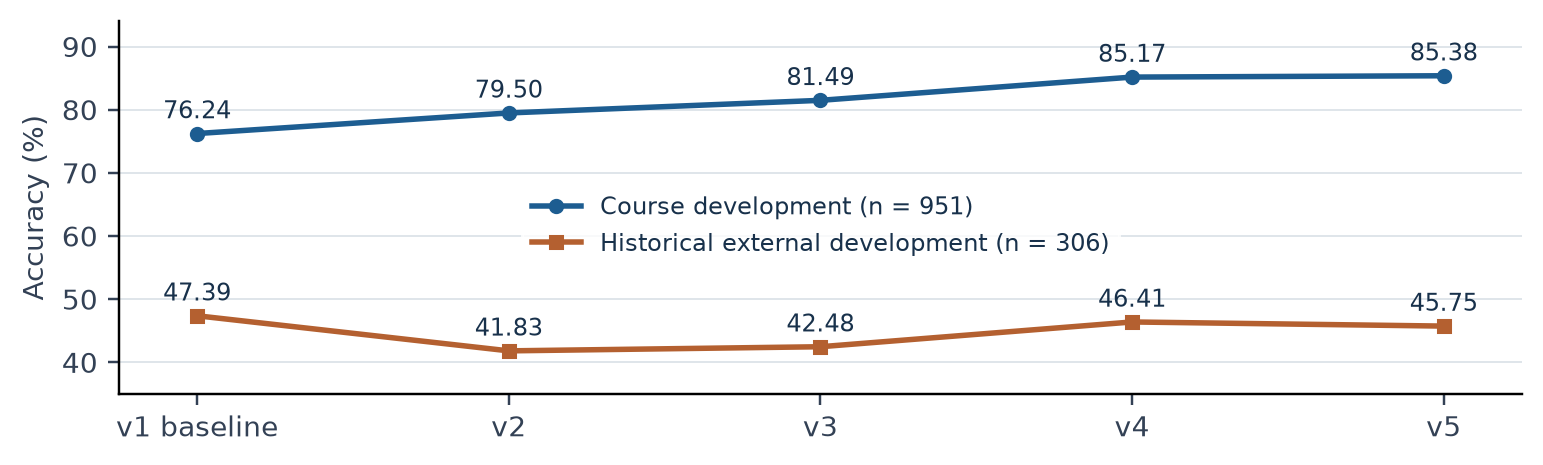

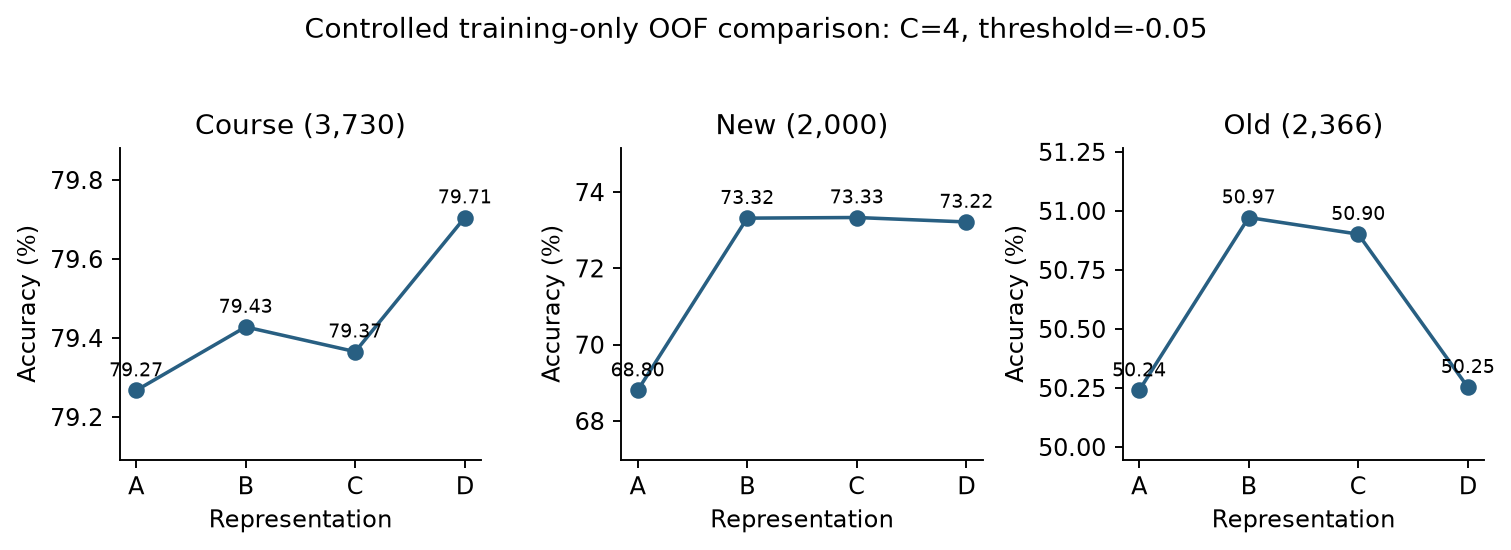

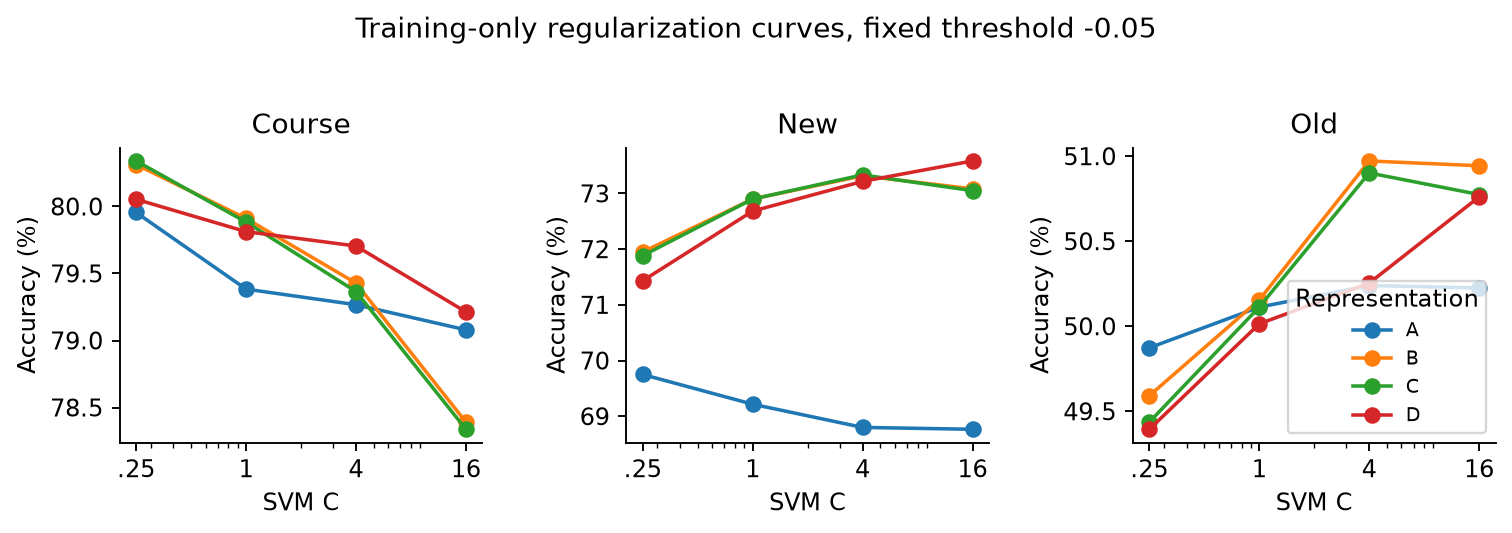

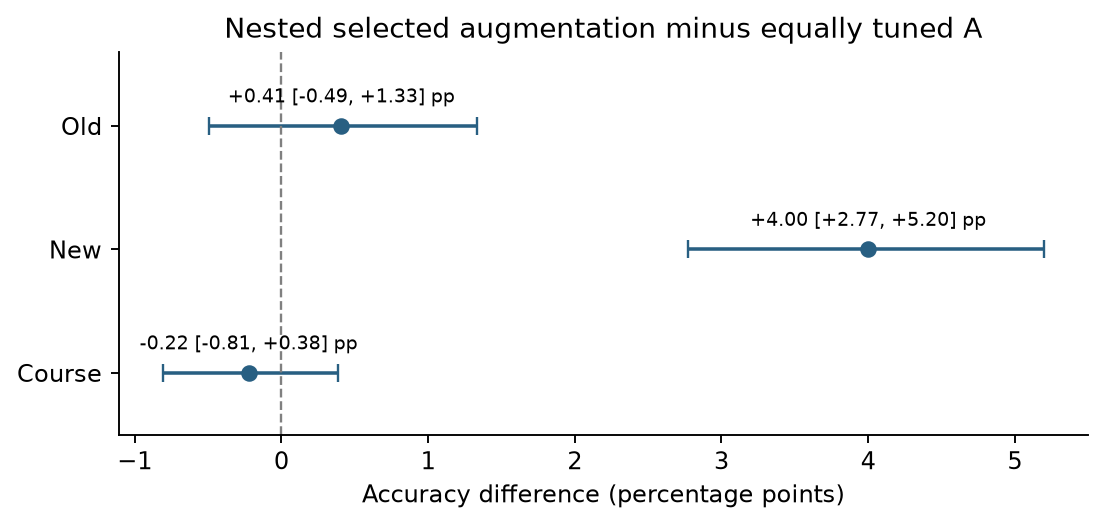

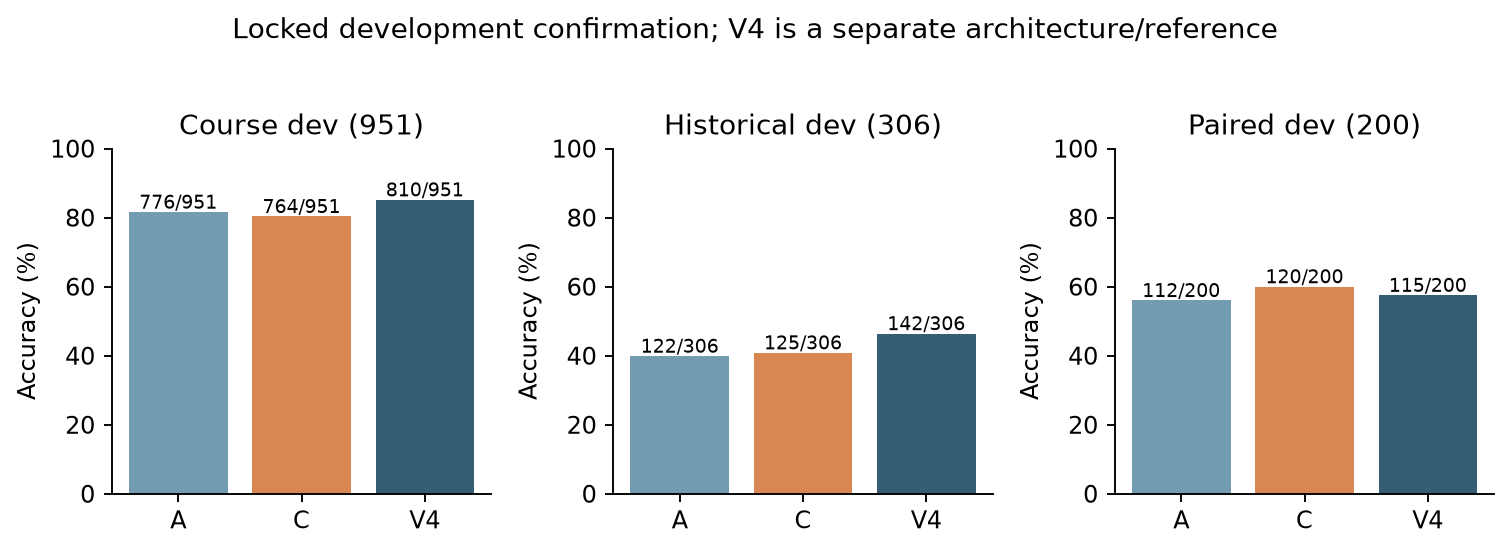

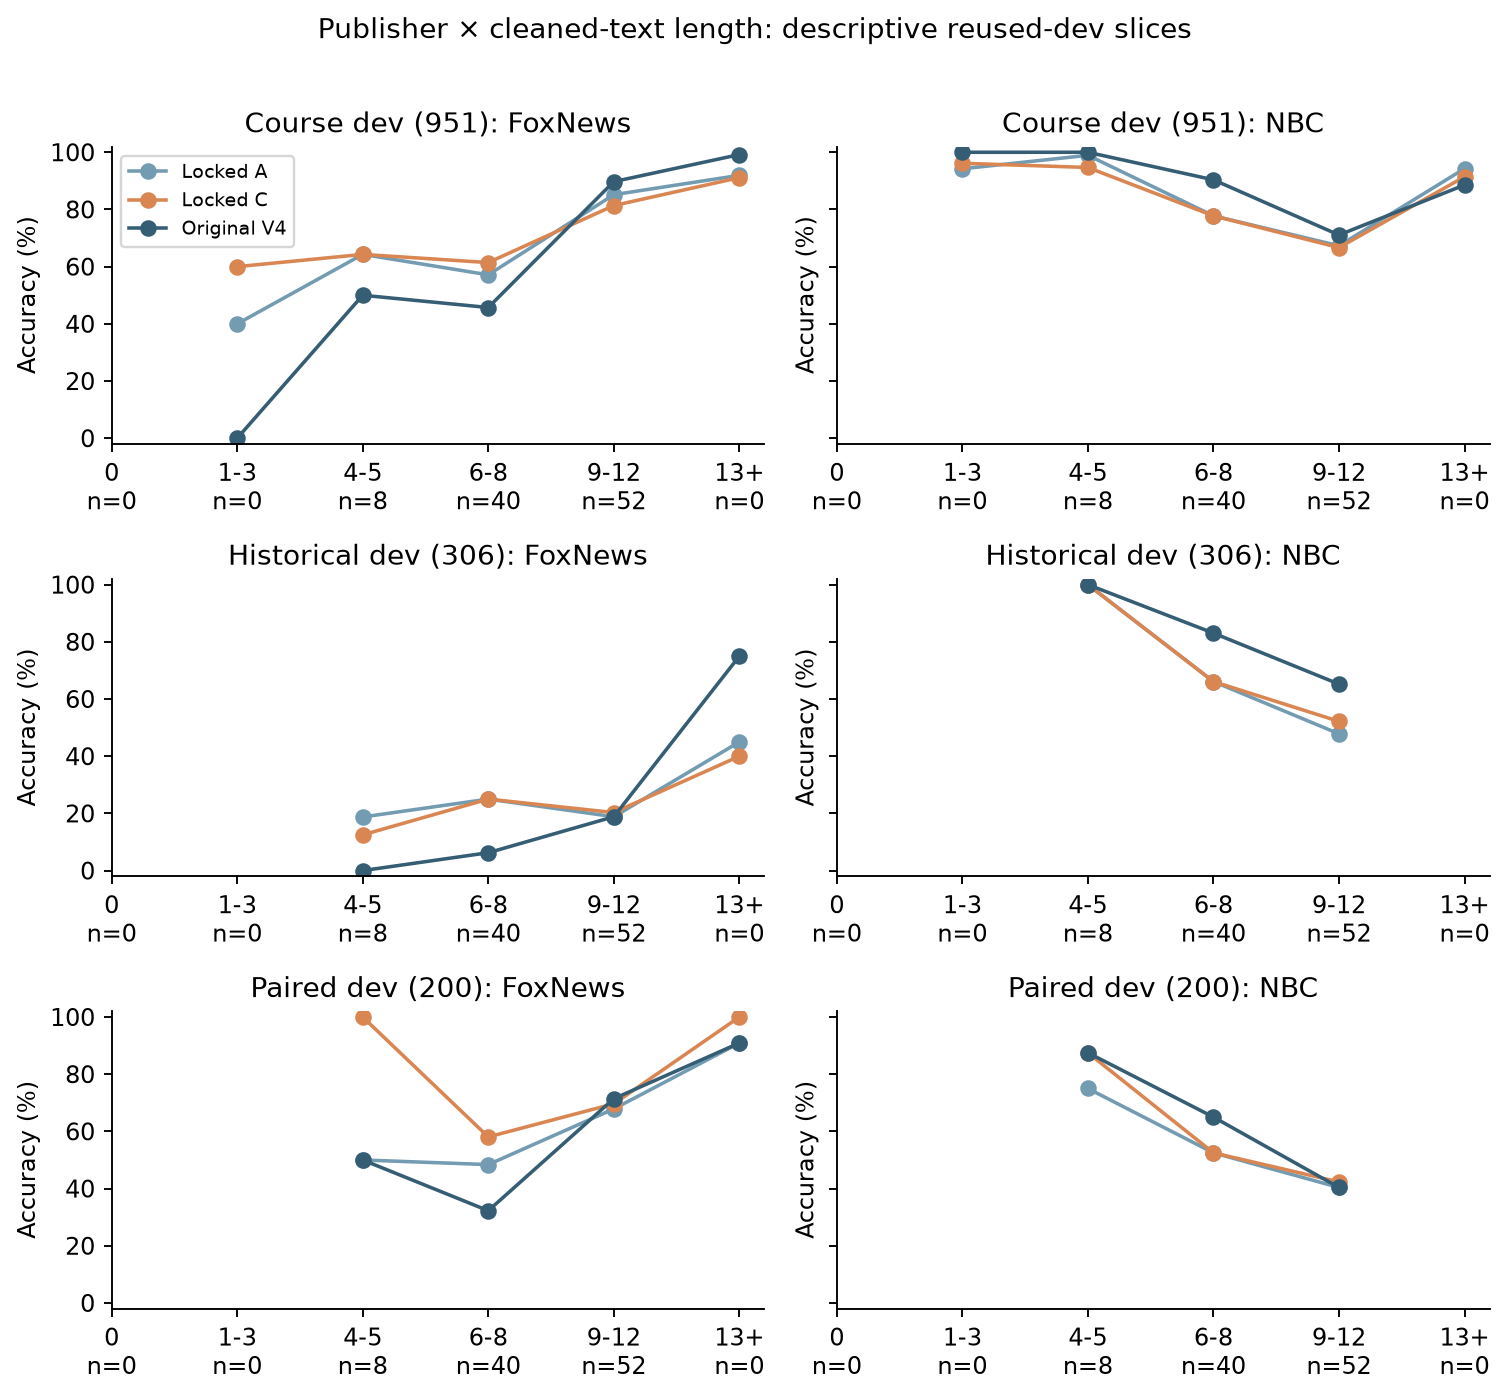

In [6]:
FIGURES = ["model_progression", "fixed_representations", "regularization_curves",
           "nested_group_intervals", "locked_development", "publisher_length_slices"]
for name in FIGURES:
    candidates = [ROOT / "report" / "figures" / (name + ".png"), RUN / "E3" / "figures" / (name + ".png")]
    found = next((path for path in candidates if path.exists()), None)
    if found is None:
        display(Markdown("**Pending figure:** " + name))
    else:
        display(Image(filename=str(found)))


## 6. E4 — conditional fixed V4 migration

**Question:** Is there sufficient evidence to spend the conditional budget on migrating the lexical adaptation to V4?

E4 may start only when E1 internal protection gates and E2 development gates both pass, and the revised budget/protocol is approved. A failed prerequisite produces a documented **not-started** decision. It must not be reported as completed V4 training or a negative V4 accuracy result. The V3 scale, threshold, and C do not automatically transfer to V4. Any supervised neural component used inside a validation fold must be trained without that fold's outcomes.


### Decide whether E4 may start

The historical code below records whether the E1/E2 prerequisites were met. The review uses the saved decision.


In [ ]:
if False:  # Historical command. Kept disabled in this review notebook.
    """E4 prerequisite decision only; this module never fits or loads a model.
    
    Conditional authorization does not override the frozen E1/E2 protection gates.
    An unmet prerequisite records E4 as not started, rather than completed training.
    """
    # from __future__ import annotations
    
    import argparse
    import json
    import math
    from pathlib import Path
    
    
    def read_result(root, relative):
        expected = root / relative
        if expected.resolve(strict=True) != expected:
            raise PermissionError("Redirected stage result rejected.")
        return json.loads(expected.read_text())
    
    
    def main():
        parser = argparse.ArgumentParser(description=__doc__)
        parser.add_argument("--run", required=True, type=Path)
        parser.add_argument("--output", required=True, type=Path)
        args = parser.parse_args()
        root, output = args.run.resolve(strict=True), args.output.resolve()
        if output.exists() and any(output.iterdir()):
            raise FileExistsError("E4 gate output must be new or empty.")
        internal = read_result(root, "E1/nested_results.json")
        dev = read_result(root, "E2/results.json")
        if dev["status"] != "complete" or dev["model_fits"] != 2:
            raise ValueError("E4 requires the complete two-fit E2 confirmation.")
        baseline = dev["models"]["tuned_course"]["development"]
        candidate = dev["models"]["augmented"]["development"]
        a, c = baseline["course_dev"], candidate["course_dev"]
        n, nbc_n = a["n"], a["per_class"]["NBC"]["support"]
        if c["n"] != n or c["per_class"]["NBC"]["support"] != nbc_n:
            raise ValueError("A/C development denominators differ.")
        a_nbc, c_nbc = a["confusion_matrix"][1][1], c["confusion_matrix"][1][1]
        checks = {
            "E1_complete_nine_outer_folds": internal.get("nested_completed_outer_folds") == 9,
            "E1_internal_gate": bool(internal["internal_gate_passed"]),
            "G5_course_accuracy": c["accuracy"] >= a["accuracy"] - .005,
            "G5_course_NBC_recall": c["per_class"]["NBC"]["recall"] >= a["per_class"]["NBC"]["recall"] - .01,
            "G6_both_external_panels_non_decreasing": all(candidate[panel]["correct"] >= baseline[panel]["correct"] for panel in ("external_dev", "paired_dev")),
            "G6_at_least_one_external_panel_improved": any(candidate[panel]["correct"] > baseline[panel]["correct"] for panel in ("external_dev", "paired_dev")),
        }
        passed = all(checks.values())
        failures = [name for name, value in checks.items() if not value]
        record = {
            "stage": "E4", "status": "prerequisites_passed_pending_training" if passed else "not_started_gate_failed",
            "conditionally_authorized": True, "conditional_cpu_cap_seconds": 600,
            "prerequisites_passed": passed, "checks": checks, "failed_prerequisites": failures,
            "reason": ("Prerequisites passed; this decision does not itself execute or complete V4 training." if passed else
                       "The conditionally authorized V4 migration was not started because the frozen E1/E2 prerequisite gates failed: " + ", ".join(failures)),
            "course_protection": {"n": n, "A_correct": a["correct"], "C_correct": c["correct"],
                                  "delta_correct": c["correct"] - a["correct"],
                                  "delta_accuracy": c["accuracy"] - a["accuracy"],
                                  "maximum_accuracy_loss": .005,
                                  "maximum_extra_errors": math.floor(.005 * n + 1e-9)},
            "NBC_protection": {"n": nbc_n, "A_true_positives": a_nbc, "C_true_positives": c_nbc,
                               "delta_true_positives": c_nbc - a_nbc,
                               "delta_recall": c["per_class"]["NBC"]["recall"] - a["per_class"]["NBC"]["recall"],
                               "maximum_recall_loss": .01,
                               "maximum_extra_misses": math.floor(.01 * nbc_n + 1e-9)},
            "external_development": {panel: {"n": baseline[panel]["n"],
                                              "A_correct": baseline[panel]["correct"],
                                              "C_correct": candidate[panel]["correct"]}
                                     for panel in ("external_dev", "paired_dev")},
            "model_training_started": False, "model_fits": 0, "new_model_predictions": 0,
            "existing_models_overwritten": False, "final_test_accessed": False,
            "source_files": ["E1/nested_results.json", "E2/results.json"],
            "interpretation": "A prerequisite decision is not a trained V4 experiment and has no V4 accuracy result.",
        }
        output.mkdir(parents=True, exist_ok=True)
        (output / "gate_decision.json").write_text(json.dumps(record, indent=2) + "\n")
        print(json.dumps(record, indent=2), flush=True)
    
    
    if __name__ == "__main__":
        main()


In [7]:
if nested and locked:
    prerequisites = bool(nested["internal_gate_passed"] and locked["development_gate_passed"])
    display({"E1_and_E2_prerequisites_pass": prerequisites,
             "interpretation": "Consult approved E4 protocol and execution record." if prerequisites else
                               "E4 must not start; this is a failed prerequisite, not completed V4 training."})
e4 = saved("e4")
if e4:
    display(e4)


{'E1_and_E2_prerequisites_pass': False,
 'interpretation': 'E4 must not start; this is a failed prerequisite, not completed V4 training.'}

{'stage': 'E4',
 'status': 'not_started_gate_failed',
 'conditionally_authorized': True,
 'conditional_cpu_cap_seconds': 600,
 'prerequisites_passed': False,
 'checks': {'E1_complete_nine_outer_folds': True,
  'E1_internal_gate': True,
  'G5_course_accuracy': False,
  'G5_course_NBC_recall': False,
  'G6_both_external_panels_non_decreasing': True,
  'G6_at_least_one_external_panel_improved': True},
 'failed_prerequisites': ['G5_course_accuracy', 'G5_course_NBC_recall'],
 'reason': 'The conditionally authorized V4 migration was not started because the frozen E1/E2 prerequisite gates failed: G5_course_accuracy, G5_course_NBC_recall',
 'course_protection': {'n': 951,
  'A_correct': 776,
  'C_correct': 764,
  'delta_correct': -12,
  'delta_accuracy': -0.012618296529968487,
  'maximum_accuracy_loss': 0.005,
  'maximum_extra_errors': 4},
 'NBC_protection': {'n': 475,
  'A_true_positives': 387,
  'C_true_positives': 382,
  'delta_true_positives': -5,
  'delta_recall': -0.010526315789473717,
 

## 7. E5 — freeze the final model with provenance

**Question:** Which artifact is retained, and which data fitted it?

The freeze stage copies the chosen submission into a new release directory and verifies its provenance. Original checkpoints remain unchanged. The original V4 validated result (810/951) belongs to the model fitted on 3,849 rows. The original V4 submission fitted all 4,800 provided rows; it has no independent course-development score from those same rows.

Source: `E5/final_decision.json` and the copied release provenance.


### Record the frozen V4 and verify its deployment interface

Source: [v4_release_checks.py](src/dragonthree/v4_release_checks.py)


In [8]:
freeze = saved("freeze")
if freeze:
    display({key: value for key, value in freeze.items() if key not in ("files", "E1_status")})


{'status': 'complete',
 'stage': 'E5',
 'decision': 'retain_original_v4_submission',
 'reason': 'E4 was conditionally authorized but was not started because the locked augmented model failed the course development protection gates. The original V4 remains the approved fallback.',
 'training_rows': 4800,
 'training_includes_course_development': True,
 'independent_course_dev_accuracy_for_submission': None,
 'validated_sibling_course_dev': {'correct': 810,
  'n': 951,
  'training_rows': 3849},
 'E2_development_gate_passed': False,
 'new_training_performed': False,
 'original_models_overwritten': False,
 'release_path': 'release/submission_v4',
 'leaderboard_submitted': False,
 'new_leaderboard_result': None}

### V4 submission and inference

These two cells preserve the submission interface after the E5 model decision. They define preprocessing and inference. Running the definitions alone does not load a checkpoint or make predictions. Reproducing the original E6 benchmark requires the separately supplied three-file submission package, including the matching checkpoint.


#### preprocess.py

Reads input CSV records in order and converts URL paths into headline text. This is the input contract for the V4 inference interface.


In [ ]:
"""Project B preprocessing: full training URLs and hidden test paths use the same text.

Only this file and model.py are needed at inference, alongside the checkpoint.
Labels come from training hosts; hosts are NEVER used as model features.
"""
from __future__ import annotations

import csv
import re
from pathlib import Path
from urllib.parse import unquote, urlparse


LABEL_TO_ID = {"FoxNews": 0, "NBC": 1}


def label_from_url(url: str) -> str:
    host = (urlparse(url.strip()).hostname or "").lower()
    for domain, label in (("foxnews.com", "FoxNews"), ("nbcnews.com", "NBC")):
        if host == domain or host.endswith("." + domain):
            return label
    return ""  # Hidden test inputs have no label.


def url_to_text(url: str) -> str:
    """Mirror the course evaluator: final slug, no sections or digit-containing words."""
    path = urlparse(url.strip()).path
    segments = [part for part in path.split("/") if part]
    tail = unquote(segments[-1]) if segments else ""
    tail = re.sub(r"\.(html?|shtml|php)$", "", tail, flags=re.IGNORECASE)
    words = [word for word in re.split(r"[-_]+", tail) if word and not re.search(r"\d", word)]
    return " ".join(words)


def text_group(text: str) -> str:
    """Same case/punctuation normalization as the model, used to detect duplicates."""
    return " ".join(re.findall(r"[a-z0-9]+", text.lower()))


def read_urls(csv_path: str | Path) -> list[str]:
    with Path(csv_path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        if "url" not in (reader.fieldnames or []):
            raise ValueError(f"{csv_path} must have a column named 'url'.")
        return [(row.get("url") or "").strip() for row in reader]


def prepare_data(csv_path: str) -> tuple[list[str], list[str]]:
    """Return one input and label per CSV record, preserving order, including empty text.

    y contains empty strings for hidden test paths. Never filter rows here;
    training-data validation belongs in prepare_splits.py instead.
    """
    urls = read_urls(csv_path)
    return [url_to_text(url) for url in urls], [label_from_url(url) for url in urls]


#### model.py

Defines the V4 inference model and prediction interface. The matching checkpoint supplies the model state used for actual predictions.


In [ ]:
"""DragonThree v4: headline style features plus fine-tuned MiniLM.
Offline CPU inference; only NumPy, PyTorch, and Python standard library required.
Class order: FoxNews=0, NBC=1. Use the matching model.pt and preprocess.py.
MiniLM weights derive from sentence-transformers/all-MiniLM-L6-v2 (Apache-2.0).
"""
"""DragonThree v3: standalone TF-IDF linear classifier in a PyTorch state_dict.

Generated layout fixes tensor shapes so the course evaluator can load every buffer.
No sklearn objects, pickle model objects, network calls, or sidecar files are needed.
Class order: FoxNews=0, NBC=1. Learned features use headline text only.
"""

import json
import re
import unicodedata
from collections import Counter

import numpy as np
import torch
from torch import nn




def normalized_text(text):
    text = text.lower()
    if not text.isascii():
        text = "".join(c for c in unicodedata.normalize("NFKD", text) if not unicodedata.combining(c))
    return text


def features(text, analyzer, ngram_range):
    low, high = ngram_range
    if analyzer == "word":
        tokens = re.findall(r"(?u)\b\w+\b", text)
        for size in range(low, min(high, len(tokens)) + 1):
            for start in range(len(tokens) - size + 1):
                yield " ".join(tokens[start:start + size])
    elif analyzer == "char":
        text = re.sub(r"\s\s+", " ", text)
        for size in range(low, min(high, len(text)) + 1):
            for start in range(len(text) - size + 1):
                yield text[start:start + size]
    elif analyzer == "char_wb":
        # Match TfidfVectorizer's within-word character n-grams, including padding.
        for word in text.split():
            padded = " " + word + " "
            for size in range(low, high + 1):
                if len(padded) <= size:
                    yield padded
                    break
                for start in range(len(padded) - size + 1):
                    yield padded[start:start + size]
    else:
        raise ValueError(f"Unsupported analyzer: {analyzer}")



"""Publisher-neutral numeric measurements of the same cleaned headline input."""
import re
import numpy as np

FUNCTION_WORDS=set('a an the and or but of to in on at for with from by as is are was were be been being it its this that these those he she they we you i his her their our your not no will would can could should has have had do does did over under after before about into out up down how what why who when where'.split())
FEATURE_NAMES=['characters','words','mean_word_length','max_word_length','std_word_length',
               'short_word_fraction','function_word_fraction','unique_word_fraction',
               'apostrophes','commas','colons','question_marks','non_ascii','uppercase']


def numeric_features(texts):
    rows=[]
    for text in texts:
        tokens=re.findall(r'[a-z0-9]+',text.lower())
        lengths=[len(t) for t in tokens] or [0]
        count=max(len(tokens),1)
        rows.append([len(text),len(tokens),np.mean(lengths),max(lengths),np.std(lengths),
                     sum(len(t)<=3 for t in tokens)/count,
                     sum(t in FUNCTION_WORDS for t in tokens)/count,
                     len(set(tokens))/count,text.count("'")+text.count('’'),text.count(','),
                     text.count(':'),text.count('?'),sum(ord(c)>127 for c in text),
                     sum(c.isupper() for c in text)])
    return np.asarray(rows,dtype=np.float64)

"""Offline MiniLM inference using PyTorch and a plain WordPiece vocabulary.

Architecture follows BERT/MiniLM. No transformers, tokenizers, downloads, or
external files are needed by the generated three-file course submission.
"""
import math
import re
import unicodedata
import torch
from torch import nn
from torch.nn import functional as F


class WordPiece:
    def __init__(self, vocabulary):
        self.vocabulary={word:i for i,word in enumerate(vocabulary)}
        self.special=re.compile(r'(\[UNK\]|\[SEP\]|\[PAD\]|\[CLS\]|\[MASK\])')

    @staticmethod
    def chinese(code):
        return any(a<=code<=b for a,b in ((0x4E00,0x9FFF),(0x3400,0x4DBF),
            (0x20000,0x2A6DF),(0x2A700,0x2B73F),(0x2B740,0x2B81F),
            (0x2B820,0x2CEAF),(0xF900,0xFAFF),(0x2F800,0x2FA1F)))

    def encode(self,text):
        output=[]
        for part in self.special.split(text):
            if not part:continue
            if self.special.fullmatch(part):
                output.append(self.vocabulary[part]);continue
            cleaned=[]
            for c in part:
                category=unicodedata.category(c)
                if ord(c) in (0,0xfffd) or (category in ('Cc','Cf') and c not in '\t\n\r'):
                    continue
                if c in ' \t\n\r' or category=='Zs':cleaned.append(' ')
                elif self.chinese(ord(c)):cleaned.extend((' ',c,' '))
                else:cleaned.append(c)
            cleaned=''.join(cleaned).lower()
            cleaned=''.join(c for c in unicodedata.normalize('NFD',cleaned) if unicodedata.category(c)!='Mn')
            pieces=[];current=[]
            for c in cleaned:
                code=ord(c)
                punctuation=(33<=code<=47 or 58<=code<=64 or 91<=code<=96 or 123<=code<=126
                             or unicodedata.category(c).startswith('P'))
                if c.isspace() or punctuation:
                    if current:pieces.append(''.join(current));current=[]
                    if punctuation:pieces.append(c)
                else:current.append(c)
            if current:pieces.append(''.join(current))
            for word in pieces:
                if len(word)>100:output.append(100);continue
                start=0;sub=[]
                while start<len(word):
                    end=len(word);found=None
                    while start<end:
                        token=word[start:end] if start==0 else '##'+word[start:end]
                        if token in self.vocabulary:
                            found=self.vocabulary[token];break
                        end-=1
                    if found is None:sub=[100];break
                    sub.append(found);start=end
                output.extend(sub)
        return [101]+output[:62]+[102]

    def batch(self,texts):
        rows=[self.encode(text) for text in texts]
        width=max(map(len,rows),default=2)
        ids=torch.zeros((len(rows),width),dtype=torch.long)
        mask=torch.zeros_like(ids)
        for i,row in enumerate(rows):
            ids[i,:len(row)]=torch.tensor(row);mask[i,:len(row)]=1
        return ids,mask


class BertEmbeddings(nn.Module):
    def __init__(self):
        super().__init__()
        self.word_embeddings=nn.Embedding(30522,384,padding_idx=0)
        self.position_embeddings=nn.Embedding(512,384)
        self.token_type_embeddings=nn.Embedding(2,384)
        self.LayerNorm=nn.LayerNorm(384,eps=1e-12)

    def forward(self,ids):
        positions=torch.arange(ids.shape[1],device=ids.device)
        return self.LayerNorm(self.word_embeddings(ids)+self.position_embeddings(positions)
                              +self.token_type_embeddings(torch.zeros_like(ids)))


class BertSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.query=nn.Linear(384,384);self.key=nn.Linear(384,384);self.value=nn.Linear(384,384)

    def forward(self,hidden,mask):
        def heads(layer):return layer(hidden).view(hidden.shape[0],hidden.shape[1],12,32).transpose(1,2)
        attended=F.scaled_dot_product_attention(heads(self.query),heads(self.key),heads(self.value),
            attn_mask=mask[:,None,None,:].bool(),dropout_p=0.)
        return attended.transpose(1,2).contiguous().view(hidden.shape[0],hidden.shape[1],384)


class BertSelfOutput(nn.Module):
    def __init__(self):
        super().__init__();self.dense=nn.Linear(384,384);self.LayerNorm=nn.LayerNorm(384,eps=1e-12)

    def forward(self,hidden,residual):return self.LayerNorm(self.dense(hidden)+residual)


class BertAttention(nn.Module):
    def __init__(self):
        super().__init__();self.add_module('self',BertSelfAttention());self.output=BertSelfOutput()

    def forward(self,hidden,mask):return self.output(getattr(self,'self')(hidden,mask),hidden)


class BertIntermediate(nn.Module):
    def __init__(self):
        super().__init__();self.dense=nn.Linear(384,1536)

    def forward(self,hidden):return F.gelu(self.dense(hidden))


class BertOutput(nn.Module):
    def __init__(self):
        super().__init__();self.dense=nn.Linear(1536,384);self.LayerNorm=nn.LayerNorm(384,eps=1e-12)

    def forward(self,hidden,residual):return self.LayerNorm(self.dense(hidden)+residual)


class BertLayer(nn.Module):
    def __init__(self):
        super().__init__();self.attention=BertAttention();self.intermediate=BertIntermediate();self.output=BertOutput()

    def forward(self,hidden,mask):
        hidden=self.attention(hidden,mask)
        return self.output(self.intermediate(hidden),hidden)


class BertEncoder(nn.Module):
    def __init__(self):
        super().__init__();self.layer=nn.ModuleList([BertLayer() for _ in range(6)])

    def forward(self,hidden,mask):
        for layer in self.layer:hidden=layer(hidden,mask)
        return hidden


class MiniLM(nn.Module):
    def __init__(self):
        super().__init__();self.embeddings=BertEmbeddings();self.encoder=BertEncoder()

    def forward(self,ids,mask):return self.encoder(self.embeddings(ids),mask)


class SemanticClassifier(nn.Module):
    def __init__(self):
        super().__init__();self.encoder=MiniLM();self.head=nn.Linear(384,1)

    def forward(self,ids,mask):
        hidden=self.encoder(ids,mask)
        pooled=(hidden*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
        return self.head(F.normalize(pooled,p=2,dim=1)).squeeze(1)

"""Combined source classifier; export.py inlines these three helper modules."""
import json
from collections import Counter
import numpy as np
import torch
from torch import nn

LAYOUT = [{'features': 43226, 'metadata_bytes': 620241}, {'features': 55553, 'metadata_bytes': 416404}]
VOCAB_BYTES = 231508
NEURAL_MODELS = 2


class Model(nn.Module):
    def __init__(self):
        super().__init__()
        torch.set_num_threads(min(torch.get_num_threads(),4))
        for i,shape in enumerate(LAYOUT):
            self.register_buffer(f'metadata_{i}',torch.zeros(shape['metadata_bytes'],dtype=torch.uint8))
            for key in ('idf','weight','interaction'):
                self.register_buffer(f'{key}_{i}',torch.zeros(shape['features'],dtype=torch.float64))
        self.register_buffer('numeric_mean',torch.zeros(14,dtype=torch.float64))
        self.register_buffer('numeric_scale',torch.ones(14,dtype=torch.float64))
        self.register_buffer('numeric_weight',torch.zeros(14,dtype=torch.float64))
        self.register_buffer('bias',torch.zeros(1,dtype=torch.float64))
        self.register_buffer('semantic_factor',torch.zeros(1,dtype=torch.float64))
        self.register_buffer('vocabulary',torch.zeros(VOCAB_BYTES,dtype=torch.uint8))
        self.semantic=nn.ModuleList([SemanticClassifier() for _ in range(NEURAL_MODELS)])
        self._cache=None;self._tokenizer=None

    def load_state_dict(self,*args,**kwargs):
        result=super().load_state_dict(*args,**kwargs)
        self._cache=None;self._tokenizer=None
        return result

    def _decode(self):
        if self._cache is None:
            if not LAYOUT:raise RuntimeError('Use generated model.py and its matching model.pt.')
            blocks=[]
            for i in range(len(LAYOUT)):
                meta=json.loads(getattr(self,f'metadata_{i}').cpu().numpy().tobytes().decode())
                vocab={term:j for j,term in enumerate(meta.pop('terms'))}
                arrays=[getattr(self,f'{key}_{i}').cpu().numpy() for key in ('idf','weight','interaction')]
                blocks.append((meta,vocab,*arrays))
            self._cache=blocks
            self._tokenizer=WordPiece(self.vocabulary.cpu().numpy().tobytes().decode().splitlines())
        return self._cache

    @torch.inference_mode()
    def decision_function(self,batch):
        texts=list(batch)
        if not texts:return np.empty(0,dtype=np.float64)
        blocks=self._decode()
        z=(numeric_features(texts)-self.numeric_mean.numpy())/self.numeric_scale.numpy()
        scores=z@self.numeric_weight.numpy()+self.bias.item()
        length=np.clip(z[:,0],-3,3)
        for row,original in enumerate(texts):
            text=normalized_text(original)
            for config,vocabulary,idf,weights,interaction in blocks:
                counts=Counter(features(text,config['analyzer'],config['ngram_range']))
                present=[(vocabulary[t],n) for t,n in counts.items() if t in vocabulary]
                if not present:continue
                indices=np.fromiter((item[0] for item in present),dtype=np.int64)
                values=np.fromiter((item[1] for item in present),dtype=np.float64)
                if config['binary']:values.fill(1.)
                if config['sublinear_tf']:values=1.+np.log(values)
                values*=idf[indices]
                if config['norm']=='l2':values/=max(np.linalg.norm(values),1e-12)
                elif config['norm'] is not None:raise ValueError('Unsupported norm')
                scores[row]+=np.dot(values,weights[indices]+interaction[indices]*length[row])
        for start in range(0,len(texts),64):
            ids,mask=self._tokenizer.batch(texts[start:start+64])
            neural=torch.stack([m(ids,mask) for m in self.semantic]).mean(0).numpy()
            scores[start:start+len(neural)]+=neural*self.semantic_factor.item()
        return scores

    def forward(self,batch):
        scores=torch.from_numpy(self.decision_function(batch))
        return torch.stack((-scores,scores),dim=1)

    def predict(self,batch):
        return ['NBC' if s>0 else 'FoxNews' for s in self.decision_function(batch)]


def get_model():return Model()


# Modified by DragonThree: task fine-tuning, classifier heads, and offline runtime.
# Pretrained source: sentence-transformers/all-MiniLM-L6-v2, revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
PRETRAINED_WEIGHT_LICENSE = 'Copyright 2018- The Hugging Face team. All rights reserved.\n\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n'


## 8. E6 — deployment interface and CPU timing

**Question:** Does the frozen three-file package satisfy the course CPU inference contract locally?

Checks cover CPU loading, row preservation and order, empty/digit-only inputs, host-independent features, and label/logit interfaces. The 8,000-row timing fixture repeats approved training URL paths; it is **not the teacher dataset**, and no fixture accuracy is computed. Each repeat reports preprocessing, loading, inference, total wall time, and CPU time. There are three repeats at one thread and three at four threads. The course limit is 420 seconds; the local target is 210 seconds. Local hardware timing does not guarantee identical server performance.

Source: `E6/interface_checks.json`, `E6/runtime.json`. The experiment CPU supervisor accounts for process costs separately from these per-repeat timings.


### Inspect the diagnostic inference implementation used alongside the deployment checks

Source: [lexical_model.py](src/dragonthree/lexical_model.py)


In [9]:
runtime = saved("runtime")
if runtime:
    display(pd.DataFrame(runtime["runs"]))
    display({key: value for key, value in runtime.items() if key != "runs"})


,threads,repeat,rows,preprocess_wall_seconds,load_wall_seconds,inference_wall_seconds,total_wall_seconds,cpu_seconds
0,1,1,8000,0.045717,0.217588,18.367626,18.630972,18.572567
1,1,2,8000,0.045544,0.229830,18.290268,18.565674,18.477801
2,1,3,8000,0.046179,0.249828,17.987556,18.283588,18.163690
3,4,1,8000,0.047488,0.236445,13.192476,13.476440,23.146289
4,4,2,8000,0.050527,0.259161,13.198958,13.508681,23.244326
5,4,3,8000,0.052984,0.287161,13.228695,13.568879,23.368820


{'status': 'complete',
 'stage': 'E6',
 'torch': '2.9.1',
 'fixture': '8000 repeated approved training URL paths; no held-out or teacher data',
 'accuracy_computed': False,
 'cold_load_each_repeat': True,
 'process_import_time_included': False,
 'teacher_limit_wall_seconds': 420,
 'local_target_wall_seconds': 210,
 'all_runs_below_target': True,
 'server_hardware_equivalence': 'unknown; local timing is not a server guarantee'}

## 9. Final evidence table and outstanding submission tasks

The bilingual tables in E3 explain what was done, why, and the recorded outcome. A table generated before a later stage finishes will explicitly show it as pending. This notebook always displays the saved state; it never turns a plan into an experiment result.

The remaining course submission work can include team-confirmed contributions, Group ID, final report template/page checks, the actual leaderboard submission/result, a Hugging Face dataset URL, and a video in which all three members speak. Unknown completion states remain unknown. No new leaderboard result can be inferred from local development accuracy or CPU deployment checks.


In [10]:
summary = saved("table")
if summary:
    display(pd.DataFrame(summary)[["id", "status", "what", "why", "result"]])
master = saved("master")
if master:
    display(pd.DataFrame(master["records"]))


,id,status,what,why,result
0,E0,complete,Audit approved inputs; reproduce original vali...,Establish input contracts and a trustworthy fa...,course_dev: 810/951; legacy_dev: 142/306; pair...
1,E1,complete,Complete the missing nested fold without chang...,Estimate the selection procedure using all thr...,Nested 9/9 folds; internal gate=True. course -...
2,E2,complete,"Fit/export locked A and C once, then confirm o...",Measure transfer after internal selection with...,"course_dev: A 776/951, C 764/951; external_dev..."
3,E3,complete,"Summarize paired errors, length slices, interv...",Explain where changes occur and quantify condi...,"course_dev: fixed 22, new errors 34, persisten..."
4,E4,not_started_gate_failed,Conditionally migrate the fixed lexical adapta...,Require internal and development protection ga...,The conditionally authorized V4 migration was ...
5,E5,complete,Freeze the final model and its provenance,Keep validated scoring separate from the full-...,Decision=retain_original_v4_submission; fittin...
6,E6,complete,Verify deployment interfaces and CPU runtime,Check the course inference contract on approve...,"1 threads, 3 repeats: 18.28–18.63s wall; 4 thr..."


,experiment,model,evaluation_level,panel,n_per_partition_or_panel,correct,correct_by_partition,accuracy,balanced_accuracy,macro_f1,roc_auc,fox_recall,nbc_recall,classifier_fit_rows_full_model,source
0,historical,V1 baseline,reused development,course_dev,951,725.0,,0.762355,NaN,NaN,NaN,NaN,NaN,3849.0,evidence/results/v1_metrics.json
1,historical,V2,reused development,course_dev,951,756.0,,0.794953,NaN,NaN,NaN,NaN,NaN,3849.0,evidence/results/v3_comparison.json
2,historical,V3,reused development,course_dev,951,775.0,,0.814932,NaN,NaN,NaN,NaN,NaN,3849.0,evidence/results/v3_comparison.json
3,historical,V4,reused development,course_dev,951,810.0,,0.851735,NaN,NaN,NaN,NaN,NaN,3849.0,evidence/results/v4_manifest.json
4,historical,V5,reused development,course_dev,951,812.0,,0.853838,NaN,NaN,NaN,NaN,NaN,3849.0,evidence/results/v5_results.json
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,E2,tuned_course,reused development,external_dev,306,122.0,,0.398693,0.398693,0.383524,0.386262,0.241830,0.555556,3730.0,E2/results.json
109,E2,tuned_course,reused development,paired_dev,200,112.0,,0.560000,0.560000,0.557166,0.599500,0.640000,0.480000,3730.0,E2/results.json
110,E2,augmented,reused development,course_dev,951,764.0,,0.803365,0.803366,0.803365,0.896732,0.802521,0.804211,5730.0,E2/results.json
111,E2,augmented,reused development,external_dev,306,125.0,,0.408497,0.408497,0.390203,0.396600,0.235294,0.581699,5730.0,E2/results.json


## 10. Reproduction boundary

The analysis command is documented for a separately approved, supervised run:

```bash
PYTHONPATH=src python -m dragonthree.analyze_results \
  --run 'experiments/New Experiments' \
  --package . \
  --output 'experiments/New Experiments/E3' \
  --figure-output report/figures
```

This notebook does not execute that command. Likewise, E1/E2 fitting and E6 timing are separate explicit stage commands with CPU limits. Read the repository README, stage documentation, frozen protocol, and CPU ledger before rerunning anything. Never substitute a sealed/test path for an approved input, and never use an old runner that reads mixed metadata or overwrites original models.
